In [1]:
from notebook_cache import NotebookCache

# results and prints live on disk, so they survive kernel restarts; one folder per notebook
cache = NotebookCache('../cache/uwm')

# UWM, simplest form, built forward (cache)

One transformer **denoises** two things at once, the next 16 actions and the frame where they end, each at **its own noise level**. Which part is pure noise and which is given picks the job: policy, forward model, inverse model or video predictor. Same data, split and eval seeds as `uva.ipynb`.

### step 0 — the data, as in UVA


In [2]:
from pathlib import Path

import numpy as np
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from numpy.typing import NDArray

np.set_printoptions(precision=3, suppress=True)
REPO = Path.cwd().parent

In [3]:
@cache
def load_table():
    # straight from the table, no video decode
    ds = LeRobotDataset('dream_robot/pick_place_cube', root=REPO / 'data/robosuite/pick_place_cube')
    return (
        np.asarray(ds.hf_dataset['observation.state'], dtype=np.float32),  # state [N, 8]
        np.asarray(ds.hf_dataset['action'], dtype=np.float32),  # action [N, 8]
        np.asarray(ds.hf_dataset['episode_index'], dtype=np.int64),  # episode [N], which demo
    )

load_table: cached, 1 call(s) stored


In [4]:
state, action, episode = load_table()
val_eps = np.random.default_rng(0).permutation(25)[:5]  # same 5 held-out demos as uva
is_val = np.isin(episode, val_eps)  # [N]
print(f'{state.shape=}  {action.shape=}  {val_eps=}  train {(~is_val).sum()}  val {is_val.sum()}')

state.shape=(5288, 8)  action.shape=(5288, 8)  val_eps=array([19,  4, 10, 11, 24])  train 4218  val 1070


### step 1 — what it sees, what it acts, and the frame where the acting ends

UWM's split: the chunk is steps t .. t+15, the frame to imagine is t+16, right after it. It sees UVA's 4 frames (t−12 .. t); history mattered there (step 22).


In [5]:
def rows_at(episode: NDArray[np.int64], offsets: list[int] | range) -> NDArray[np.int64]:
    # [N, len(offsets)]: the row of step t + o for every row t, clipped to t's own demo (as uva)
    first = np.searchsorted(episode, episode, side='left')  # [N]
    last = np.searchsorted(episode, episode, side='right') - 1  # [N]
    idx = np.arange(len(episode))[:, None] + np.asarray(offsets)
    return np.clip(idx, first[:, None], last[:, None]).astype(np.int64)


past = rows_at(episode, [-12, -8, -4, 0])  # what it sees: 4 frames
chunk = rows_at(episode, range(16))  # what it does: the next 16 actions
after = rows_at(episode, [16])  # what it imagines: the frame once the chunk is played
t = int(np.flatnonzero(episode == 2)[60])  # demo 2, step 60, as in uva
print(f'row {t}: past {past[t]}  chunk {chunk[t, 0]}..{chunk[t, -1]}  after {after[t]}')

row 491: past [479 483 487 491]  chunk 491..506  after [507]


### step 2 — both cameras into RAM (~20 s the first time, cached after), and row 491's frames


In [6]:
import matplotlib.pyplot as plt
import torch
from torch import Tensor

In [7]:
@cache
def load_images():
    # every frame decoded from both videos once, kept as uint8 (~0.5 GB), as act_byname step 3
    ds = LeRobotDataset('dream_robot/pick_place_cube', root=REPO / 'data/robosuite/pick_place_cube')
    top = np.zeros((len(ds), 3, 128, 128), dtype=np.uint8)  # [N, 3, H, W]
    wrist = np.zeros_like(top)
    for i in range(len(ds)):
        item: dict[str, Tensor] = ds[i]  # this frame, decoded from both videos
        top[i] = (item['observation.images.top'] * 255).round().to(torch.uint8).numpy()
        wrist[i] = (item['observation.images.wrist'] * 255).round().to(torch.uint8).numpy()
    return top, wrist

load_images: cached, 1 call(s) stored


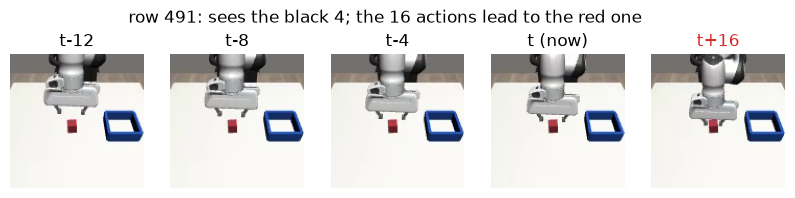

In [8]:
top, wrist = load_images()
rows = list(map(int, past[t])) + [int(after[t, 0])]  # 4 seen, 1 to imagine
names = ['t-12', 't-8', 't-4', 't (now)', 't+16']
fig = plt.figure(figsize=(10, 2.3))
for i, (row, name) in enumerate(zip(rows, names)):
    ax = fig.add_subplot(1, 5, i + 1)
    ax.imshow(np.transpose(top[row], (1, 2, 0)))
    ax.set_title(name, color='tab:red' if '+' in name else 'k')
    ax.axis('off')
fig.suptitle(f'row {t}: sees the black 4; the 16 actions lead to the red one')
plt.show()

### step 3 — the one new idea: each part is noised to its own level

Flow matching's straight line (`flow_matching.ipynb` step 2): `x_τ = (1 − τ)·noise + τ·clean`. τ = 0 is pure noise ("unknown"), τ = 1 is clean ("given"). The frame gets τ_v, the chunk τ_a, drawn independently in training. Both are put on the noise's scale first: pixels to [−1, 1], actions to std units.


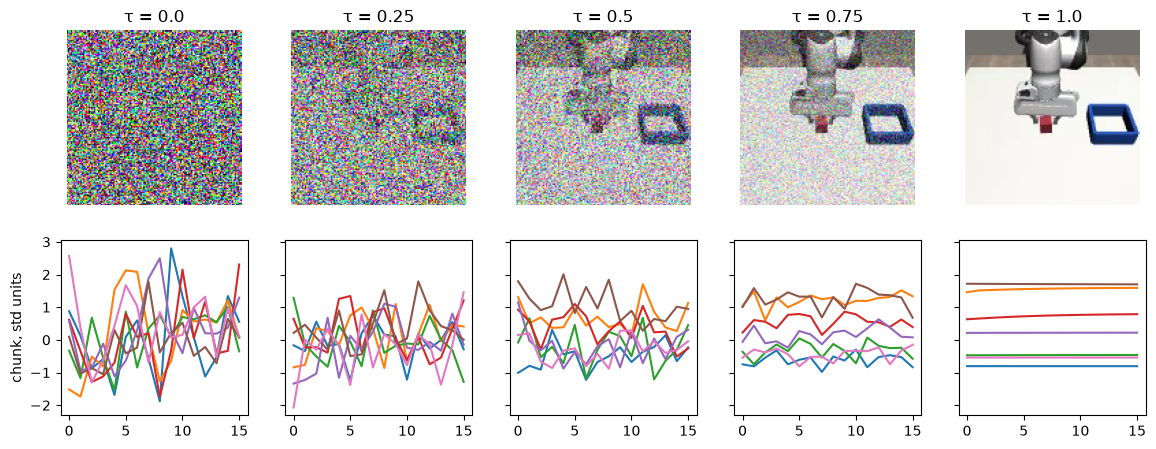

In [9]:
a_mean, a_std = action[~is_val].mean(0), action[~is_val].std(0)  # [8] each, train demos only
frame = torch.tensor(top[after[t, 0]]).float() / 255 * 2 - 1  # [3, 128, 128] in [-1, 1]
acts = torch.tensor((action[chunk[t]] - a_mean) / a_std)  # [16, 8] in std units

torch.manual_seed(0)
fig, axs = plt.subplots(2, 5, figsize=(14, 5), sharey='row')
for i, tau in enumerate([0.0, 0.25, 0.5, 0.75, 1.0]):
    v = (1 - tau) * torch.randn_like(frame) + tau * frame  # the frame at level tau
    a = (1 - tau) * torch.randn_like(acts) + tau * acts  # the chunk at level tau
    axs[0, i].imshow(((v.permute(1, 2, 0) + 1) / 2).clamp(0, 1))
    axs[0, i].set_title(f'τ = {tau}')
    axs[0, i].axis('off')
    axs[1, i].plot(a[:, :7])  # the 7 arm joints over the 16 steps
axs[1, 0].set_ylabel('chunk, std units')
plt.show()

### step 4 — the two levels pick the job

Each part is either **left as noise** (τ stays 0: unknown, ignored), **given** (τ stays 1: clean, known), or **denoised** (τ runs 0 → 1: the answer). Training draws τ_v and τ_a independently, so every pairing below is one the model has seen.

```-
job              frame τ_v     chunk τ_a     asks
policy           stays 0       0 → 1         what do I do now?
inverse model    stays 1       0 → 1         which moves get me to this frame?
forward model    0 → 1         stays 1       where do these moves take me?
video            0 → 1         stays 0       what happens next, whatever I do?
```

Below: each job halfway through, the part being answered at τ = 0.5.


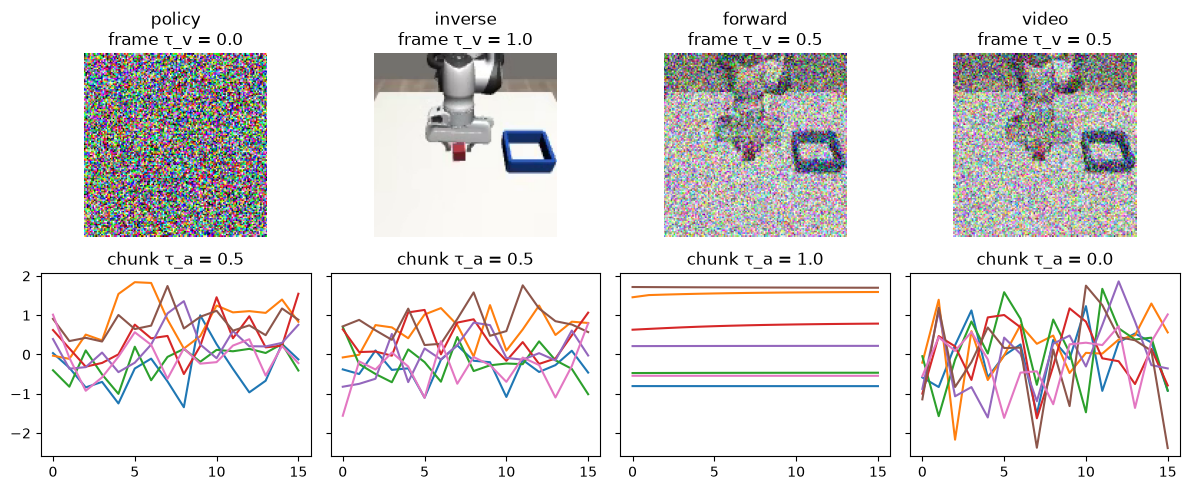

In [10]:
def noised(x: Tensor, tau: float) -> Tensor:
    # step 3's line: tau 0 is pure noise, 1 is x itself
    return (1 - tau) * torch.randn_like(x) + tau * x


# (frame tau, chunk tau) halfway through each job
jobs = {'policy': (0.0, 0.5), 'inverse': (1.0, 0.5), 'forward': (0.5, 1.0), 'video': (0.5, 0.0)}
torch.manual_seed(0)
fig, axs = plt.subplots(2, 4, figsize=(12, 5), sharey='row')
for i, (job, (tau_v, tau_a)) in enumerate(jobs.items()):
    axs[0, i].imshow(((noised(frame, tau_v).permute(1, 2, 0) + 1) / 2).clamp(0, 1))
    axs[0, i].set_title(f'{job}\nframe τ_v = {tau_v}')
    axs[0, i].axis('off')
    axs[1, i].plot(noised(acts, tau_a)[:, :7])
    axs[1, i].set_title(f'chunk τ_a = {tau_a}')
plt.tight_layout()
plt.show()

### step 5 — frames become tokens: the seen ones as in UVA, the noisy one cut into patches

Seen frames: UVA's `Patches` (4 stride-2 convs, 128 px → 8×8 grid of D-dim tokens). The noisy t+16 frame is cut into the same 8×8 grid of 16×16 px patches, and one linear map turns each patch's 768 numbers into a token. Cut-and-map, not convs, so the output head can do the exact reverse later: token → 768 numbers → patch.


In [11]:
import torch.nn.functional as F
from torch import nn

device = 'cuda'
GRID, D = 8, 128  # 8 x 8 tokens per frame, each a D-dim vector


class Patches(nn.Module):
    # uva step 3: a seen frame -> 64 tokens
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),
            nn.GELU(),  # -> [B, 32, 64, 64]
            nn.Conv2d(32, 64, 4, 2, 1),
            nn.GELU(),  # -> [B, 64, 32, 32]
            nn.Conv2d(64, 128, 4, 2, 1),
            nn.GELU(),  # -> [B, 128, 16, 16]
            nn.Conv2d(128, D, 4, 2, 1),  # -> [B, D, 8, 8]
        )

    def forward(self, x: Tensor) -> Tensor:
        # x: [B, 3, 128, 128] floats in [0, 1]
        # out: [B, 64, D], one token per patch, row by row
        grid: Tensor = self.conv(x)  # [B, D, 8, 8]
        return grid.flatten(2).transpose(1, 2)


def cut(x: Tensor) -> Tensor:
    # [B, 3, 128, 128] -> [B, 64, 768]: each 16 x 16 patch's pixels in a row, same order as Patches
    return F.unfold(x, 16, stride=16).transpose(1, 2)

In [12]:
seen = torch.tensor(top[past[t]]).to(device).float() / 255  # [4, 3, 128, 128], row 491's 4 frames
seen_tok: Tensor = Patches().to(device)(seen)  # [4, 64, D]

frame_in = nn.Linear(3 * 16 * 16, D).to(device)  # one noisy patch's 768 numbers -> one token
noisy = noised(frame, 0.5).to(device)[None]  # [1, 3, 128, 128], the t+16 frame halfway
noisy_tok: Tensor = frame_in(cut(noisy))  # [1, 64, D]
print(
    f'seen {tuple(seen_tok.shape)}   noisy t+16 {tuple(cut(noisy).shape)} -> {tuple(noisy_tok.shape)}'
)

seen (4, 64, 128)   noisy t+16 (1, 64, 768) -> (1, 64, 128)


### step 6 — the noisy chunk becomes 16 tokens, and each part is tagged with its noise level

One linear map per action: 8 numbers → a token. The tag: a small MLP turns τ (one number) into a D-dim vector, added to every token of that part. Without it the model can't tell "half-cleaned, trust it a bit" from "pure noise, ignore it" (`flow_matching.ipynb` fed t as an input for the same reason).


In [13]:
act_in = nn.Linear(8, D).to(device)  # one noisy action -> one token
tau_in = nn.Sequential(nn.Linear(1, D), nn.SiLU(), nn.Linear(D, D)).to(device)  # tau -> a tag


def tag(tau: float) -> Tensor:
    # [1, 1, D]: the same tag for every token of a part at noise level tau
    return tau_in(torch.tensor([[tau]], device=device))[:, None]


noisy_acts = noised(acts, 0.5).to(device)[None]  # [1, 16, 8], the chunk halfway
act_tok = act_in(noisy_acts) + tag(0.5)  # [1, 16, D]
frame_tok = noisy_tok + tag(0.5)  # [1, 64, D], step 5's frame tokens, tagged
print(f'chunk {tuple(noisy_acts.shape)} -> {tuple(act_tok.shape)}   frame {tuple(frame_tok.shape)}')
print(
    'tags differ by level (untrained):', [f'{(tag(x) - tag(0.0)).norm():.2f}' for x in (0.5, 1.0)]
)

chunk (1, 16, 8) -> (1, 16, 128)   frame (1, 64, 128)
tags differ by level (untrained): ['1.16', '2.36']


### step 7 — every token gets **when**, **where** and a **role**; all of it in one sequence

As uva steps 4–7: `when` = the step offset (seen −12 .. 0, actions 0 .. 15, frame +16), `where` = which patch, `role` = seen frame, noisy frame, action or joints. The joints come in as one token, at t.


In [14]:
when = nn.Embedding(12 + 16 + 1, D).to(device)  # learned, one row per step offset -12 .. +16
where = nn.Embedding(GRID * GRID, D).to(device)  # learned, one row per patch
role = nn.Embedding(4, D).to(device)  # learned: seen frame, noisy frame, action, joints
joints_in = nn.Linear(8, D).to(device)  # the arm's 8 readings -> one token


def at(offsets: list[int] | range) -> Tensor:
    # [len(offsets), D]: the `when` rows of these step offsets
    return when(torch.tensor(list(offsets), device=device) + 12)


joints_tok = joints_in(torch.tensor(state[t], device=device))  # [D], the arm now
parts = [
    seen_tok + at([-12, -8, -4, 0])[:, None] + where.weight + role.weight[0],  # [4, 64, D]
    frame_tok[0] + at([16]) + where.weight + role.weight[1],  # [64, D]
    act_tok[0] + at(range(16)) + role.weight[2],  # [16, D]
    (joints_tok + at([0])[0] + role.weight[3])[None],  # [1, D]
]
seq = torch.cat([parts[0].flatten(0, 1), *parts[1:]])  # [337, D]
print([tuple(p.shape) for p in parts], '->', tuple(seq.shape))

[(4, 64, 128), (64, 128), (16, 128), (1, 128)] -> (337, 128)


### step 8 — the transformer, and two heads that read out a **velocity** for each noisy part

The body is UVA's: 4 layers, every token reads every other. The heads differ: UVA's read out the answer itself; here they read out flow matching's velocity (`flow_matching.ipynb` step 3), the direction from noise to clean, `v = clean − noise`. Frame head: one token → its patch's 768 numbers. Action head: one token → 8 numbers.


In [15]:
layer = nn.TransformerEncoderLayer(D, 4, 4 * D, 0.0, 'gelu', batch_first=True, norm_first=True)
body = nn.TransformerEncoder(layer, 4, enable_nested_tensor=False).to(device)  # 4 layers, 4 heads
frame_out = nn.Linear(D, 3 * 16 * 16).to(device)  # one frame token -> its patch's velocity
act_out = nn.Linear(D, 8).to(device)  # one action token -> its action's velocity

out: Tensor = body(seq[None])  # [1, 337, D]
v_frame = frame_out(out[:, 256:320])  # [1, 64, 768], the 64 noisy-frame tokens
v_acts = act_out(out[:, 320:336])  # [1, 16, 8], the 16 action tokens
print(
    f'body {tuple(out.shape)}   frame velocity {tuple(v_frame.shape)}   chunk velocity {tuple(v_acts.shape)}'
)

body (1, 337, 128)   frame velocity (1, 64, 768)   chunk velocity (1, 16, 8)


### step 9 — the loss on row 491: two independent τ, two velocities, MSE on each

Steps 5–8 go into one function first (same loose pieces), so the inputs can change. Then: draw τ_v and τ_a separately, noise each part, and score each predicted velocity against the true `clean − noise`. The bar: a head that always says 0 scores the mean of `(clean − noise)²`, about `clean² + 1`: ≈ 2 for the chunk, a bit less for the frame. Untrained, both losses come out **above** that bar: the heads don't say 0, they say random numbers of their own.


In [16]:
patches = Patches().to(device)  # step 5 made one inline; keep one now


def velocities(
    seen: Tensor, joints: Tensor, x_f: Tensor, x_a: Tensor, tau_v: float, tau_a: float
) -> tuple[Tensor, Tensor]:
    # seen: [4, 3, 128, 128] in [0, 1];  joints: [8];  x_f: [64, 768] noisy patches;  x_a: [16, 8]
    # out: velocity of each noisy patch [64, 768] and each noisy action [16, 8] (steps 5-8)
    parts = [
        patches(seen) + at([-12, -8, -4, 0])[:, None] + where.weight + role.weight[0],
        frame_in(x_f) + tag(tau_v)[0] + at([16]) + where.weight + role.weight[1],
        act_in(x_a) + tag(tau_a)[0] + at(range(16)) + role.weight[2],
        (joints_in(joints) + at([0])[0] + role.weight[3])[None],
    ]
    out = body(torch.cat([parts[0].flatten(0, 1), *parts[1:]])[None])[0]  # [337, D]
    return frame_out(out[256:320]), act_out(out[320:336])


torch.manual_seed(0)
clean_f, clean_a = cut(frame[None])[0].to(device), acts.to(device)  # [64, 768], [16, 8]
noise_f, noise_a = torch.randn_like(clean_f), torch.randn_like(clean_a)
tau_v, tau_a = torch.rand(2).tolist()  # drawn independently
x_f = (1 - tau_v) * noise_f + tau_v * clean_f  # step 3's line, keeping the noise this time
x_a = (1 - tau_a) * noise_a + tau_a * clean_a
v_f, v_a = velocities(seen, torch.tensor(state[t], device=device), x_f, x_a, tau_v, tau_a)
loss_f = F.mse_loss(v_f, clean_f - noise_f)
loss_a = F.mse_loss(v_a, clean_a - noise_a)
print(f'τ_v {tau_v:.2f}  τ_a {tau_a:.2f}   frame loss {loss_f:.3f}   chunk loss {loss_a:.3f}')
print(
    f'"heads say 0" bars: frame {((clean_f - noise_f) ** 2).mean():.3f}   chunk {((clean_a - noise_a) ** 2).mean():.3f}'
)

τ_v 0.50  τ_a 0.77   frame loss 3.228   chunk loss 4.897
"heads say 0" bars: frame 1.639   chunk 1.981


### step 10 — start both heads at zero: the untrained loss drops onto the bar

Zero weights and bias in the two output layers only (DiT does this). The heads then say 0 for everything at the start, so training begins from "no opinion" instead of random velocities. Gradients still flow: a zero layer's weights get gradient `token × error`, which isn't zero.


In [17]:
for head in (frame_out, act_out):
    nn.init.zeros_(head.weight)
    nn.init.zeros_(head.bias)

# step 9's exact inputs (same noise, same τ), only the heads changed
v_f, v_a = velocities(seen, torch.tensor(state[t], device=device), x_f, x_a, tau_v, tau_a)
loss_f = F.mse_loss(v_f, clean_f - noise_f)
loss_a = F.mse_loss(v_a, clean_a - noise_a)
(loss_f + loss_a).backward()
print(f'frame loss {loss_f:.3f}   chunk loss {loss_a:.3f}   (bars 1.639, 1.981)')
print(
    f'head grads: frame {frame_out.weight.grad.norm():.3f}   chunk {act_out.weight.grad.norm():.3f}'
)

frame loss 1.639   chunk loss 1.981   (bars 1.639, 1.981)
head grads: frame 0.906   chunk 13.023


### step 11 — steps 5–10 packed into `UWM` (what training uses), batched

Same pieces, now owned by one module, and every row of a batch carries its **own** τ_v and τ_a. The joints are standardised going in (train demos' mean and std, as UVA). Heads start at zero (step 10).


In [18]:
s_mean = torch.tensor(state[~is_val].mean(0), device=device)  # [8], train demos only
s_std = torch.tensor(state[~is_val].std(0), device=device)


class UWM(nn.Module):
    def __init__(self, layers: int = 4):
        super().__init__()
        self.patches = Patches()  # seen frames -> tokens (step 5)
        self.frame_in = nn.Linear(3 * 16 * 16, D)  # noisy patch -> token (step 5)
        self.act_in = nn.Linear(8, D)  # noisy action -> token (step 6)
        self.tau_in = nn.Sequential(nn.Linear(1, D), nn.SiLU(), nn.Linear(D, D))  # tau -> tag
        self.joints_in = nn.Linear(8, D)
        self.when = nn.Embedding(12 + 16 + 1, D)  # row = step offset + 12 (step 7)
        self.where = nn.Embedding(GRID * GRID, D)
        self.role = nn.Embedding(4, D)  # seen frame, noisy frame, action, joints
        layer = nn.TransformerEncoderLayer(
            D, 4, 4 * D, 0.0, 'gelu', batch_first=True, norm_first=True
        )
        self.body = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)  # step 8
        self.frame_out = nn.Linear(D, 3 * 16 * 16)
        self.act_out = nn.Linear(D, 8)
        for head in (self.frame_out, self.act_out):  # step 10
            nn.init.zeros_(head.weight)
            nn.init.zeros_(head.bias)

    def forward(
        self, seen: Tensor, joints: Tensor, x_f: Tensor, x_a: Tensor, tau_v: Tensor, tau_a: Tensor
    ) -> tuple[Tensor, Tensor]:
        # seen: [B, 4, 3, 128, 128] in [0, 1];  joints: [B, 8] radians
        # x_f: [B, 64, 768] noisy patches;  x_a: [B, 16, 8] noisy actions;  tau_v, tau_a: [B]
        # out: velocities [B, 64, 768] and [B, 16, 8]
        B = seen.shape[0]
        when, where, role = self.when.weight, self.where.weight, self.role.weight
        grids = self.patches(seen.flatten(0, 1)).unflatten(0, (B, 4))  # [B, 4, 64, D]
        seen_tok = grids + when[[0, 4, 8, 12]][:, None] + where + role[0]  # offsets -12 .. 0
        tag_v = self.tau_in(tau_v[:, None])[:, None]  # [B, 1, D], each row its own level
        tag_a = self.tau_in(tau_a[:, None])[:, None]
        frame_tok = self.frame_in(x_f) + tag_v + when[28] + where + role[1]  # offset +16
        act_tok = self.act_in(x_a) + tag_a + when[12:28] + role[2]  # offsets 0 .. 15
        joints_tok = self.joints_in((joints - s_mean) / s_std) + when[12] + role[3]  # [B, D]
        seq = torch.cat([seen_tok.flatten(1, 2), frame_tok, act_tok, joints_tok[:, None]], 1)
        out = self.body(seq)  # [B, 337, D]
        return self.frame_out(out[:, 256:320]), self.act_out(out[:, 320:336])

In [19]:
import copy

torch.manual_seed(0)
uwm = UWM().to(device)
pair = np.array([t, int(np.flatnonzero(episode == 7)[100])])  # row 491 and one from demo 7
seen_b = torch.tensor(top[past[pair]], device=device).float() / 255  # [2, 4, 3, 128, 128]
joints_b = torch.tensor(state[pair], device=device)  # [2, 8]
x_f_b, x_a_b = torch.randn(2, 64, 768, device=device), torch.randn(2, 16, 8, device=device)
tau_v_b = torch.tensor([0.0, 1.0], device=device)  # row 0 a policy call, row 1 an inverse call
tau_a_b = torch.tensor([0.5, 0.2], device=device)
v_f, v_a = uwm(seen_b, joints_b, x_f_b, x_a_b, tau_v_b, tau_a_b)
n = sum(p.numel() for p in uwm.parameters())
print(
    f'{tuple(v_f.shape)} {tuple(v_a.shape)}   {n / 1e6:.2f}M params   all zero: {v_f.abs().max() == 0 and v_a.abs().max() == 0}'
)

# rows don't leak into each other: with random heads, row 1 alone == row 1 in the batch
probe = copy.deepcopy(uwm)
nn.init.normal_(probe.act_out.weight)
both = probe(seen_b, joints_b, x_f_b, x_a_b, tau_v_b, tau_a_b)[1][1]
alone = probe(seen_b[1:], joints_b[1:], x_f_b[1:], x_a_b[1:], tau_v_b[1:], tau_a_b[1:])[1][0]
print(f'row 1 alone vs in the batch: max diff {(both - alone).abs().max():.1e}')

(2, 64, 768) (2, 16, 8)   1.45M params   all zero: True
row 1 alone vs in the batch: max diff 1.5e-05


### step 12 — batches on the GPU, the batch loss, and what one training step costs

The data goes to the GPU once, so a batch is indexing only. Every row draws its **own** τ_v, τ_a and noise. The chunk loss skips steps past the demo's end (as UVA). Untrained (zero heads), each loss sits on its "say 0" bar. Then one forward + backward at batch 64, fp32 vs bf16 autocast (UVA: 178 vs 70 ms).


In [20]:
TOP = torch.tensor(top, device=device)  # [N, 3, 128, 128] uint8
STATE, ACTION = torch.tensor(state, device=device), torch.tensor(action, device=device)  # [N, 8]
PAST, CHUNK, AFTER = (torch.tensor(r, device=device) for r in (past, chunk, after))  # rows of rows
REAL = CHUNK == torch.arange(len(episode), device=device)[:, None] + torch.arange(16, device=device)
A_MEAN, A_STD = torch.tensor(a_mean, device=device), torch.tensor(a_std, device=device)  # step 3
TRAIN = torch.tensor(np.flatnonzero(~is_val), device=device)  # [Ntr]


def batch_loss(net: UWM, rows: Tensor) -> tuple[Tensor, Tensor]:
    # rows: [B] dataset rows on the GPU
    # out: frame and chunk velocity MSE, each row at its own random tau_v, tau_a
    clean_f = cut(TOP[AFTER[rows, 0]].float() / 255 * 2 - 1)  # [B, 64, 768] in [-1, 1]
    clean_a = (ACTION[CHUNK[rows]] - A_MEAN) / A_STD  # [B, 16, 8] std units
    noise_f, noise_a = torch.randn_like(clean_f), torch.randn_like(clean_a)
    tau_v, tau_a = torch.rand(2, len(rows), device=device)  # [B] each, drawn independently
    x_f = (1 - tau_v[:, None, None]) * noise_f + tau_v[:, None, None] * clean_f
    x_a = (1 - tau_a[:, None, None]) * noise_a + tau_a[:, None, None] * clean_a
    v_f, v_a = net(TOP[PAST[rows]].float() / 255, STATE[rows], x_f, x_a, tau_v, tau_a)
    keep = REAL[rows][..., None].float()  # [B, 16, 1], False past the demo's end
    loss_a = (((v_a - (clean_a - noise_a)) ** 2) * keep).sum() / (keep.sum() * 8)
    return F.mse_loss(v_f, clean_f - noise_f), loss_a


torch.manual_seed(0)
rows = TRAIN[torch.randint(0, len(TRAIN), (64,), device=device)]  # [64], a random train batch
loss_f, loss_a = batch_loss(uwm, rows)
bar_f = ((cut(TOP[AFTER[rows, 0]].float() / 255 * 2 - 1)) ** 2).mean() + 1  # E(clean − noise)²
print(f'untrained batch 64: frame {loss_f:.3f} (bar ≈ {bar_f:.3f})   chunk {loss_a:.3f} (bar ≈ 2)')

untrained batch 64: frame 1.655 (bar ≈ 1.655)   chunk 1.920 (bar ≈ 2)


In [21]:
import time


def time_step(amp: bool) -> tuple[float, Tensor, Tensor]:
    # out: ms per forward + backward on the batch above, and its two losses (as uva step 15)
    for i in range(11):  # the first is warm-up
        if i == 1:
            torch.cuda.synchronize()
            t0 = time.perf_counter()
        torch.manual_seed(0)  # same tau and noise every repeat
        with torch.autocast('cuda', dtype=torch.bfloat16, enabled=amp):
            loss_f, loss_a = batch_loss(uwm, rows)
        (loss_f + loss_a).backward()
    torch.cuda.synchronize()
    return (time.perf_counter() - t0) / 10 * 1000, loss_f, loss_a


for amp in (False, True):
    ms, loss_f, loss_a = time_step(amp)
    print(f'{"bf16" if amp else "fp32"}: {ms:4.0f} ms   frame {loss_f:.4f}   chunk {loss_a:.4f}')

fp32:  103 ms   frame 1.6551   chunk 1.9105
bf16:   45 ms   frame 1.6551   chunk 1.9105


### step 13 — train `UWM` (3000 steps, ~2.5 min): loss = frame velocity MSE + chunk velocity MSE

As UVA step 16: batch 64, AdamW 1e-3, bf16. Every 500 steps, the velocity losses on the 5 val demos, with the same τ and noise every time (seed fixed inside) so the numbers compare across checks. The bars to beat are step 12's: frame ≈ 1.65, chunk ≈ 2.


In [22]:
VAL = torch.tensor(np.flatnonzero(is_val), device=device)  # [Nva]


@torch.no_grad()
def val_loss(net: UWM) -> tuple[float, float]:
    # out: frame and chunk velocity MSE over every val row; same tau and noise on every call
    with torch.random.fork_rng(devices=[device]):  # don't disturb training's random stream
        torch.manual_seed(0)
        sums = [0.0, 0.0]
        for j in range(0, len(VAL), 256):
            rows = VAL[j : j + 256]
            with torch.autocast('cuda', dtype=torch.bfloat16):
                losses = batch_loss(net, rows)
            for k in range(2):
                sums[k] += losses[k].item() * len(rows)
    return sums[0] / len(VAL), sums[1] / len(VAL)


print('untrained val: frame {:.4f}   chunk {:.4f}'.format(*val_loss(uwm)))

untrained val: frame 1.6563   chunk 1.9774


In [23]:
@cache
def train(seed: int = 0, steps: int = 3000, lr: float = 1e-3) -> dict[str, Tensor]:
    torch.manual_seed(seed)
    net = UWM().to(device)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    for step in range(steps + 1):
        rows = TRAIN[torch.randint(0, len(TRAIN), (64,), device=device)]  # [64]
        with torch.autocast('cuda', dtype=torch.bfloat16):  # step 12
            loss_f, loss_a = batch_loss(net, rows)
        opt.zero_grad()
        (loss_f + loss_a).backward()
        opt.step()
        if step % 500 == 0:
            val_f, val_a = val_loss(net)
            print(
                f'{step:5d}  train frame {loss_f.item():.4f} chunk {loss_a.item():.4f}'
                f'   val frame {val_f:.4f} chunk {val_a:.4f}'
            )
    return {k: v.cpu() for k, v in net.state_dict().items()}

train: cached, 2 call(s) stored


In [24]:
uwm = UWM().to(device)
uwm.load_state_dict(train())
uwm.eval();

    0  train frame 1.6550 chunk 1.9200   val frame 1.4840 chunk 1.9707
  500  train frame 0.9754 chunk 0.1617   val frame 0.9812 chunk 0.1421
 1000  train frame 0.9550 chunk 0.0861   val frame 0.9537 chunk 0.1065
 1500  train frame 0.9361 chunk 0.0848   val frame 0.9420 chunk 0.0893
 2000  train frame 0.9301 chunk 0.0677   val frame 0.9345 chunk 0.0788
 2500  train frame 0.9280 chunk 0.0703   val frame 0.9266 chunk 0.0743
 3000  train frame 0.9061 chunk 0.0521   val frame 0.9186 chunk 0.0596


### step 14 — the policy job: frame left as noise, chunk denoised in 10 steps; first-action error on val

Step 4's first row. The frame sits at τ_v = 0 (fresh noise, never touched); the chunk starts as noise and follows the predicted velocity for 10 Euler steps (`flow_matching.ipynb` step 4). Then the same number UVA and ACT reported: mean |error| of each val chunk's first action, radians (UVA: arm 0.0062, gripper 0.0231; ACT ChunkNet 0.0064, 0.0461).


In [25]:
@torch.no_grad()
def sample_chunk(net: UWM, rows: Tensor, steps: int = 10, inverse: bool = False) -> Tensor:
    # policy job: frame stays pure noise at tau_v = 0, chunk denoised from noise
    # inverse job (step 15): frame given clean at tau_v = 1, the real t+16 frame
    # out: [B, 16, 8] radians
    B = len(rows)
    if inverse:
        x_f = cut(TOP[AFTER[rows, 0]].float() / 255 * 2 - 1)  # [B, 64, 768], where it must end up
    else:
        x_f = torch.randn(B, 64, 768, device=device)  # never touched
    tau_v = torch.full((B,), float(inverse), device=device)
    x_a = torch.randn(B, 16, 8, device=device)  # start: fresh noise
    for k in range(steps):  # Euler: move at the predicted velocity for 1/steps
        tau_a = torch.full((B,), k / steps, device=device)
        with torch.autocast('cuda', dtype=torch.bfloat16):
            _, v_a = net(TOP[PAST[rows]].float() / 255, STATE[rows], x_f, x_a, tau_v, tau_a)
        x_a = x_a + v_a.float() / steps
    return x_a * A_STD + A_MEAN


torch.manual_seed(0)
first = torch.cat([sample_chunk(uwm, VAL[j : j + 256])[:, 0] for j in range(0, len(VAL), 256)])
err = (first - ACTION[VAL]).abs().mean(0)  # [8], radians
print(f'val first action |error|: arm {err[:7].mean():.4f}   gripper {err[7]:.4f}')
print('(UVA: arm 0.0062, gripper 0.0231;  ACT ChunkNet: 0.0064, 0.0461)')

val first action |error|: arm 0.0073   gripper 0.0311
(UVA: arm 0.0062, gripper 0.0231;  ACT ChunkNet: 0.0064, 0.0461)


### step 15 — the inverse job: the same weights, but the t+16 frame is **given**

Step 4's second row: τ_v = 1 and the frame slot holds the real frame the chunk ends at. Same sampler, same val rows, same score, now at every step of the chunk. If knowing the end helps, the error drops below the policy's. It does, but only by ~10% on the arm, and about evenly along the chunk: the end frame doesn't pin the late actions down any more than the early ones.


policy   first action: arm 0.0073 gripper 0.0311   whole chunk: arm 0.0087 gripper 0.0270
inverse  first action: arm 0.0066 gripper 0.0252   whole chunk: arm 0.0081 gripper 0.0257


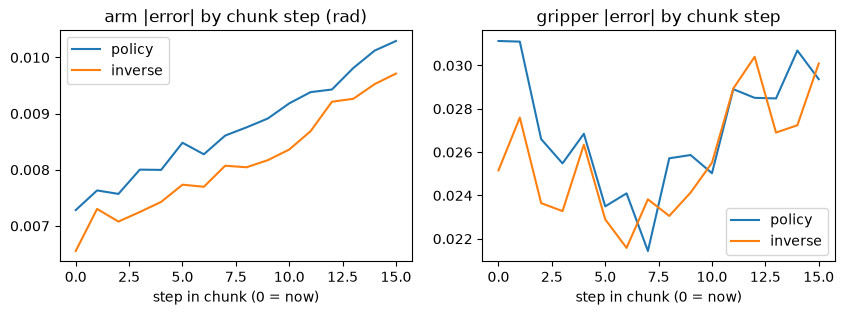

In [26]:
def chunk_error(inverse: bool) -> Tensor:
    # out: [16, 8] mean |error| at each chunk step, radians, over val rows (real steps only)
    torch.manual_seed(0)
    got = torch.cat(
        [sample_chunk(uwm, VAL[j : j + 256], inverse=inverse) for j in range(0, len(VAL), 256)]
    )
    keep = REAL[VAL][..., None].float()  # [Nva, 16, 1]
    return ((got - ACTION[CHUNK[VAL]]).abs() * keep).sum(0) / keep.sum(0)


errs = {'policy': chunk_error(False), 'inverse': chunk_error(True)}
for job, e in errs.items():
    print(
        f'{job:8s} first action: arm {e[0, :7].mean():.4f} gripper {e[0, 7]:.4f}'
        f'   whole chunk: arm {e[:, :7].mean():.4f} gripper {e[:, 7].mean():.4f}'
    )
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
for job, e in errs.items():
    axs[0].plot(e[:, :7].mean(1).cpu(), label=job)
    axs[1].plot(e[:, 7].cpu(), label=job)
axs[0].set_title('arm |error| by chunk step (rad)')
axs[1].set_title('gripper |error| by chunk step')
for ax in axs:
    ax.set_xlabel('step in chunk (0 = now)')
    ax.legend()
plt.show()

### step 16 — the sim, and `predict(seen, obs)`: frame history in, a sampled chunk out

As UVA step 18: the caller keeps every top frame since reset, and before step 12 the first frame stands in. New: each call runs the policy job (frame left as noise, 10 denoising passes) instead of one forward pass. Then one episode, seed 1000, playing 8 of each 16.


In [27]:
import logging
import os

os.environ.setdefault('MUJOCO_GL', 'egl')  # render without a window; before mujoco loads
logging.disable(logging.WARNING)  # robosuite warns while importing; mute that
import robosuite  # noqa: E402, F401

logging.disable(logging.NOTSET)
logging.getLogger('robosuite_logs').setLevel(logging.ERROR)

from dream_robot.core.registry import make_env  # noqa: E402

env = make_env('robosuite/pick_place_cube')  # as uva step 18


@torch.no_grad()
def predict(net: UWM, seen: list[np.ndarray], obs, steps: int = 10) -> np.ndarray:
    # seen: every top frame since reset, [H, W, 3] uint8 each, newest last
    # out: [16, 8], a chunk sampled by the policy job (step 14's loop, for one live observation)
    now = len(seen) - 1
    ims = np.stack([seen[max(0, now + o)] for o in (-12, -8, -4, 0)])  # [4, H, W, 3]
    past_ims = torch.from_numpy(ims).permute(0, 3, 1, 2)[None].to(device).float() / 255
    joints = torch.from_numpy(obs.state)[None].to(device)  # [1, 8]
    x_f = torch.randn(1, 64, 768, device=device)  # frame left as noise
    tau_v = torch.zeros(1, device=device)
    x_a = torch.randn(1, 16, 8, device=device)
    for k in range(steps):
        tau_a = torch.full((1,), k / steps, device=device)
        with torch.autocast('cuda', dtype=torch.bfloat16):
            _, v_a = net(past_ims, joints, x_f, x_a, tau_v, tau_a)
        x_a = x_a + v_a.float() / steps
    chunk_np = (x_a * A_STD + A_MEAN)[0].cpu().numpy()  # [16, 8] radians
    chunk_np[:, 7] = np.clip(chunk_np[:, 7], 0.0, 1.0)  # gripper commands must stay in [0, 1]
    return chunk_np


def rollout(net: UWM, seed: int, n_exec: int) -> tuple[bool, str, int]:
    # as uva step 19: predict a chunk, play its first n_exec actions blind, predict again
    # out: (success, failure mode, steps taken)
    obs = env.reset(seed=seed)
    seen = [obs.images['top']]
    plan = []  # actions still to play from the last chunk
    for step in range(600):
        if not plan:
            plan = list(predict(net, seen, obs)[:n_exec])  # n_exec x [8]
        r = env.step(plan.pop(0))
        obs = r.observation
        seen.append(obs.images['top'])
        if r.terminated or r.truncated:
            break
    return r.success, str(r.failure_mode), step + 1


torch.manual_seed(0)
t0 = time.perf_counter()
ok, mode, steps = rollout(uwm, 1000, n_exec=8)
print(
    f'seed 1000: {"SUCCESS" if ok else mode}  after {steps} steps  ({time.perf_counter() - t0:.1f} s)'
)

seed 1000: no_grasp  after 600 steps  (3.1 s)


### step 17 — how many steps to play blind? 20 seeds each (~4 min)

Same 20 unseen seeds as uva step 20 (UVA: 20, 19, 19, 20 of 20 at n_exec 1, 4, 8, 16; rerun 20, 19, 19, 20).


In [28]:
import contextlib
import io
from collections import Counter


@cache
def sweep(n_exec: int, train_seed: int = 0, train_steps: int = 3000) -> dict[int, tuple]:
    # the 20 eval seeds at one n_exec, with the weights train(train_seed, train_steps) gives
    # out: {env seed: (success, failure mode, steps)}
    net = UWM().to(device)
    with contextlib.redirect_stdout(io.StringIO()):  # train's replayed log isn't this cell's
        net.load_state_dict(train(seed=train_seed, steps=train_steps))
    net.eval()
    torch.manual_seed(n_exec)  # the sampling noise, fixed per call
    res = {seed: rollout(net, seed, n_exec) for seed in range(1000, 1020)}
    fails = Counter(mode for ok, mode, _ in res.values() if not ok)
    print(
        f'n_exec {n_exec:2d}: {sum(ok for ok, _, _ in res.values()):2d}/20   failures {dict(fails)}'
    )
    return res

sweep: cached, 4 call(s) stored


In [29]:
sweeps = {n_exec: sweep(n_exec) for n_exec in [8, 16]}  # ~1 min each the first time
print('UVA: 20, 19, 19, 20 /20')

n_exec  8:  8/20   failures {'no_grasp': 11, 'dropped': 1}
n_exec 16: 10/20   failures {'no_grasp': 10}
UVA: 20, 19, 19, 20 /20


### step 18 — undertrained? Same model, 10000 steps (~8 min), then the same score and sweep

At 3000 steps the chunk loss was still falling (0.079 → 0.060 over the last 1000), and `flow_matching.ipynb` needed 30k steps for 80/80. Only `steps` changes, so the 3000-step results stay cached next to these.


In [30]:
uwm10k = UWM().to(device)
uwm10k.load_state_dict(train(steps=10000))
uwm10k.eval();

    0  train frame 1.6550 chunk 1.9200   val frame 1.4840 chunk 1.9707
  500  train frame 0.9754 chunk 0.1614   val frame 0.9812 chunk 0.1421
 1000  train frame 0.9550 chunk 0.0868   val frame 0.9537 chunk 0.1081
 1500  train frame 0.9361 chunk 0.0841   val frame 0.9420 chunk 0.0899
 2000  train frame 0.9297 chunk 0.0657   val frame 0.9340 chunk 0.0817
 2500  train frame 0.9287 chunk 0.0732   val frame 0.9260 chunk 0.0759
 3000  train frame 0.9061 chunk 0.0530   val frame 0.9186 chunk 0.0595
 3500  train frame 0.9056 chunk 0.0438   val frame 0.9113 chunk 0.0660
 4000  train frame 0.8990 chunk 0.0419   val frame 0.9057 chunk 0.0639
 4500  train frame 0.9017 chunk 0.0438   val frame 0.9037 chunk 0.0598
 5000  train frame 0.9037 chunk 0.0313   val frame 0.9013 chunk 0.0627
 5500  train frame 0.8895 chunk 0.0371   val frame 0.8958 chunk 0.0659
 6000  train frame 0.8870 chunk 0.0508   val frame 0.8935 chunk 0.0610
 6500  train frame 0.8892 chunk 0.0528   val frame 0.8922 chunk 0.0583
 7000 

In [31]:
torch.manual_seed(0)  # as step 14
first = torch.cat([sample_chunk(uwm10k, VAL[j : j + 256])[:, 0] for j in range(0, len(VAL), 256)])
err = (first - ACTION[VAL]).abs().mean(0)  # [8], radians
print(f'10k val first action |error|: arm {err[:7].mean():.4f}   gripper {err[7]:.4f}')
print('(3k: arm 0.0073, gripper 0.0311;  UVA: 0.0062, 0.0231)')

10k val first action |error|: arm 0.0059   gripper 0.0223
(3k: arm 0.0073, gripper 0.0311;  UVA: 0.0062, 0.0231)


In [32]:
sweeps10k = {n_exec: sweep(n_exec, train_steps=10000) for n_exec in [8, 16]}
print('3k: 8/20, 10/20;  UVA: 19/20, 20/20')

n_exec  8: 16/20   failures {'dropped': 2, 'no_grasp': 2}
n_exec 16: 16/20   failures {'dropped': 2, 'no_grasp': 2}
3k: 8/20, 10/20;  UVA: 19/20, 20/20


### step 19 — the frame half: the video job and the forward job, same weights, no training

Step 4's last two rows. **Video**: the chunk stays noise (τ_a = 0), the t+16 frame is denoised from noise. **Forward**: the real chunk is given (τ_a = 1), the frame is denoised: "if I do these 16 moves, what will I see?". Shown on held-out demo 19 at the two moments uva step 17 used, next to the true frame; pixel MSE over all val rows against the "nothing moves" bar (the frame now, copied).


In [33]:
@torch.no_grad()
def sample_frame(net: UWM, rows: Tensor, forward: bool = False, steps: int = 10) -> Tensor:
    # video job: chunk stays noise at tau_a = 0;  forward job: the real chunk given at tau_a = 1
    # out: [B, 3, 128, 128] in [0, 1], the imagined t+16 frame
    B = len(rows)
    if forward:
        x_a = (ACTION[CHUNK[rows]] - A_MEAN) / A_STD  # [B, 16, 8], the moves actually made
    else:
        x_a = torch.randn(B, 16, 8, device=device)  # never touched
    tau_a = torch.full((B,), float(forward), device=device)
    x_f = torch.randn(B, 64, 768, device=device)  # start: fresh noise
    for k in range(steps):  # Euler, as sample_chunk, now on the frame
        tau_v = torch.full((B,), k / steps, device=device)
        with torch.autocast('cuda', dtype=torch.bfloat16):
            v_f, _ = net(TOP[PAST[rows]].float() / 255, STATE[rows], x_f, x_a, tau_v, tau_a)
        x_f = x_f + v_f.float() / steps
    frames = F.fold(x_f.transpose(1, 2), 128, 16, stride=16)  # cut's reverse: patches -> frame
    return ((frames + 1) / 2).clamp(0, 1)

In [34]:
torch.manual_seed(0)
truth = lambda rows: TOP[AFTER[rows, 0]].float() / 255  # [B, 3, 128, 128], the real t+16 frame
mse = {'copy now': 0.0, 'video': 0.0, 'forward': 0.0}  # pixel MSE over all val rows
for j in range(0, len(VAL), 256):
    rows, n = VAL[j : j + 256], min(256, len(VAL) - j) / len(VAL)
    mse['copy now'] += F.mse_loss(TOP[rows].float() / 255, truth(rows)).item() * n
    mse['video'] += F.mse_loss(sample_frame(uwm10k, rows), truth(rows)).item() * n
    mse['forward'] += F.mse_loss(sample_frame(uwm10k, rows, True), truth(rows)).item() * n
print({k: round(v, 4) for k, v in mse.items()})

{'copy now': 0.0173, 'video': 0.1142, 'forward': 0.1141}


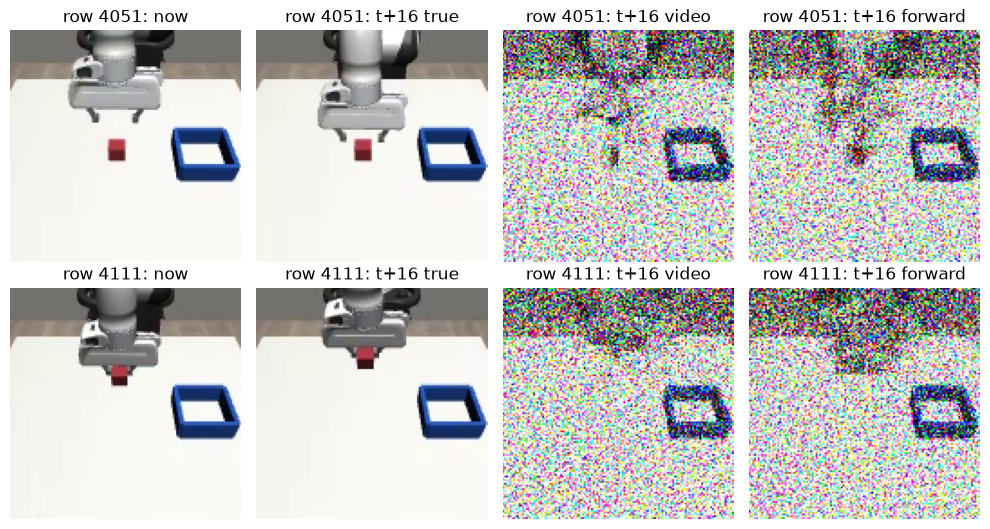

In [35]:
torch.manual_seed(0)
moments = torch.tensor([int(np.flatnonzero(episode == 19)[s]) for s in (40, 100)], device=device)
shown = {
    'now': TOP[moments].float() / 255,
    't+16 true': truth(moments),
    't+16 video': sample_frame(uwm10k, moments),
    't+16 forward': sample_frame(uwm10k, moments, True),
}
fig, axs = plt.subplots(2, 4, figsize=(10, 5.4))
for i, (name, ims) in enumerate(shown.items()):
    for m in range(2):
        axs[m, i].imshow(ims[m].permute(1, 2, 0).cpu())
        axs[m, i].set_title(f'row {moments[m].item()}: {name}')
        axs[m, i].axis('off')
plt.tight_layout()
plt.show()

### step 20 — the frame head predicts the **clean patch**; its velocity is derived from it

Step 19's frames kept their noise: each patch's 768 numbers pass through a 128-wide token, too narrow to carry 768 independent noise values, so the head can't output the noise part of `clean − noise`. Fix (Li & He 2025): the head outputs the clean patch ĉ, which is smooth and fits; the noise is read off the input `x` itself:

```-
x = (1 − τ)·noise + τ·clean      ⇒   noise = (x − τ·clean) / (1 − τ)
v = clean − noise = (clean − x) / (1 − τ)       ⇒   v̂ = (ĉ − x) / (1 − τ)
```

Only the frame head changes; the action head, the loss on v, the sampler and the training loop stay as they are. `1 − τ` is floored at 0.05 so τ_v near 1 can't divide by ~0.


In [36]:
class UWMx(UWM):
    # UWM whose frame head says the clean patch; the frame velocity is derived from it (step 20)
    def forward(
        self, seen: Tensor, joints: Tensor, x_f: Tensor, x_a: Tensor, tau_v: Tensor, tau_a: Tensor
    ) -> tuple[Tensor, Tensor]:
        clean_hat, v_a = super().forward(seen, joints, x_f, x_a, tau_v, tau_a)  # [B, 64, 768]
        left = (1 - tau_v).clamp(min=0.05)[:, None, None]  # how much noise is left, floored
        return (clean_hat - x_f) / left, v_a  # v̂ = (ĉ − x) / (1 − τ)

In [37]:
torch.manual_seed(0)
batch = TRAIN[torch.randint(0, len(TRAIN), (64,), device=device)]  # step 12's batch
for net in (UWM().to(device), UWMx().to(device)):  # both untrained, heads at zero
    torch.manual_seed(1)  # same tau and noise for both
    loss_f, loss_a = batch_loss(net, batch)
    print(f'{type(net).__name__:5s} untrained: frame {loss_f:.3f}   chunk {loss_a:.3f}')

UWM   untrained: frame 1.656   chunk 1.849
UWMx  untrained: frame 33.287   chunk 1.849


### step 21 — train `UWMx`, 10000 steps (~8 min)

Step 13's loop, building `UWMx`. A function of its own, so the cached `UWM` runs (3k, 10k) stay valid. The frame loss is now weighted by `1/(1 − τ)²` (step 20), so its numbers don't compare with `UWM`'s; the chunk loss does.


In [38]:
@cache
def train_x(seed: int = 0, steps: int = 10000, lr: float = 1e-3) -> dict[str, Tensor]:
    # step 13's train(), building UWMx
    torch.manual_seed(seed)
    net = UWMx().to(device)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    for step in range(steps + 1):
        rows = TRAIN[torch.randint(0, len(TRAIN), (64,), device=device)]  # [64]
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss_f, loss_a = batch_loss(net, rows)
        opt.zero_grad()
        (loss_f + loss_a).backward()
        opt.step()
        if step % 500 == 0:
            val_f, val_a = val_loss(net)
            print(
                f'{step:5d}  train frame {loss_f.item():.4f} chunk {loss_a.item():.4f}'
                f'   val frame {val_f:.4f} chunk {val_a:.4f}'
            )
    return {k: v.cpu() for k, v in net.state_dict().items()}

train_x: cached, 1 call(s) stored


In [39]:
uwmx = UWMx().to(device)
uwmx.load_state_dict(train_x())
uwmx.eval();

    0  train frame 26.4847 chunk 1.9200   val frame 22.3193 chunk 1.9707
  500  train frame 0.3157 chunk 0.2257   val frame 0.4877 chunk 0.2053
 1000  train frame 0.3706 chunk 0.1025   val frame 0.3705 chunk 0.1310
 1500  train frame 0.1877 chunk 0.0930   val frame 0.2958 chunk 0.1072
 2000  train frame 0.1701 chunk 0.0803   val frame 0.2791 chunk 0.0896
 2500  train frame 0.2540 chunk 0.0825   val frame 0.2335 chunk 0.0841
 3000  train frame 0.1762 chunk 0.0693   val frame 0.2146 chunk 0.0725
 3500  train frame 0.1504 chunk 0.0451   val frame 0.2029 chunk 0.0665
 4000  train frame 0.1102 chunk 0.0438   val frame 0.1974 chunk 0.0694
 4500  train frame 0.1641 chunk 0.0488   val frame 0.1966 chunk 0.0654
 5000  train frame 0.2880 chunk 0.0346   val frame 0.1820 chunk 0.0628
 5500  train frame 4.1675 chunk 0.2837   val frame 3.7453 chunk 0.3619
 6000  train frame 0.1494 chunk 0.0619   val frame 0.2140 chunk 0.0635
 6500  train frame 0.1595 chunk 0.0552   val frame 0.1887 chunk 0.0630
 700

### step 22 — step 19 again, on `UWMx`: are the imagined frames clean now?

Same pixel MSE over the val rows, same two moments of demo 19. Bars from step 19: copy-now 0.0173; `UWM` video 0.1142, forward 0.1141.


In [40]:
torch.manual_seed(0)
mse_x = {'video': 0.0, 'forward': 0.0}  # pixel MSE over all val rows, as step 19
for j in range(0, len(VAL), 256):
    rows, n = VAL[j : j + 256], min(256, len(VAL) - j) / len(VAL)
    mse_x['video'] += F.mse_loss(sample_frame(uwmx, rows), truth(rows)).item() * n
    mse_x['forward'] += F.mse_loss(sample_frame(uwmx, rows, True), truth(rows)).item() * n
print({k: round(v, 4) for k, v in mse_x.items()}, '  UWM: 0.1142, 0.1141;  copy now 0.0173')

{'video': 0.0139, 'forward': 0.0134}   UWM: 0.1142, 0.1141;  copy now 0.0173


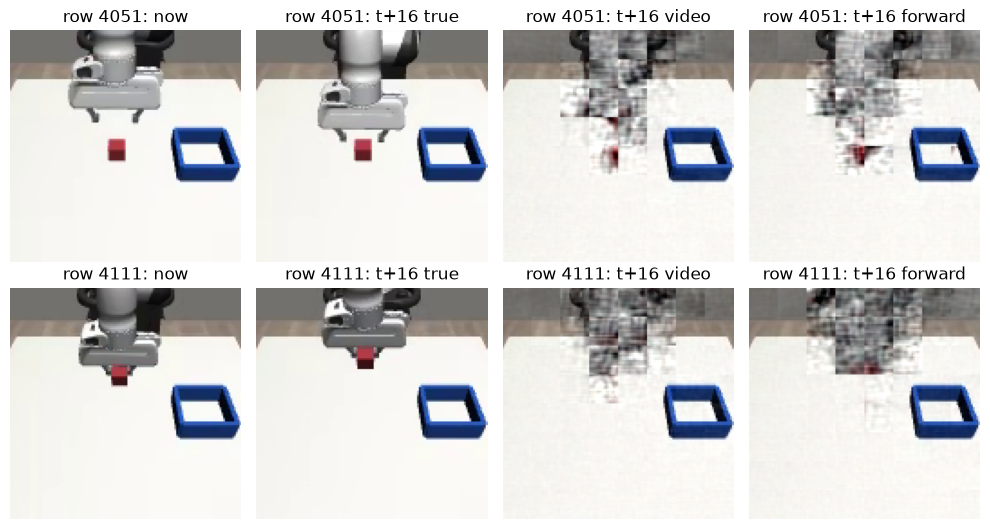

In [41]:
torch.manual_seed(0)
shown = {
    'now': TOP[moments].float() / 255,
    't+16 true': truth(moments),
    't+16 video': sample_frame(uwmx, moments),
    't+16 forward': sample_frame(uwmx, moments, True),
}
fig, axs = plt.subplots(2, 4, figsize=(10, 5.4))
for i, (name, ims) in enumerate(shown.items()):
    for m in range(2):
        axs[m, i].imshow(ims[m].permute(1, 2, 0).cpu())
        axs[m, i].set_title(f'row {moments[m].item()}: {name}')
        axs[m, i].axis('off')
plt.tight_layout()
plt.show()

### step 23 — does `UWMx` still act? The same sweep, n_exec 8 and 16

Step 17's `sweep`, built on `UWMx` and `train_x`. `UWM` 10k: 16/20, 16/20; UVA: 19/20, 20/20.


In [42]:
@cache
def sweep_x(n_exec: int, train_seed: int = 0, train_steps: int = 10000) -> dict[int, tuple]:
    # step 17's sweep(), with the weights train_x(train_seed, train_steps) gives
    net = UWMx().to(device)
    with contextlib.redirect_stdout(io.StringIO()):  # train_x's replayed log isn't this cell's
        net.load_state_dict(train_x(seed=train_seed, steps=train_steps))
    net.eval()
    torch.manual_seed(n_exec)  # the sampling noise, fixed per call
    res = {seed: rollout(net, seed, n_exec) for seed in range(1000, 1020)}
    fails = Counter(mode for ok, mode, _ in res.values() if not ok)
    print(
        f'n_exec {n_exec:2d}: {sum(ok for ok, _, _ in res.values()):2d}/20   failures {dict(fails)}'
    )
    return res

sweep_x: cached, 2 call(s) stored


In [43]:
sweeps_x = {n_exec: sweep_x(n_exec) for n_exec in [8, 16]}
print('UWM 10k: 16/20, 16/20;  UVA: 19/20, 20/20')

n_exec  8:  3/20   failures {'no_grasp': 16, 'dropped': 1}
n_exec 16:  6/20   failures {'no_grasp': 14}
UWM 10k: 16/20, 16/20;  UVA: 19/20, 20/20


### step 24 — did the action half get weaker? Step 14's first-action error on `UWMx`

No sim, a few seconds. `UWM` 10k: arm 0.0059, gripper 0.0223.


In [44]:
torch.manual_seed(0)  # as step 14
first = torch.cat([sample_chunk(uwmx, VAL[j : j + 256])[:, 0] for j in range(0, len(VAL), 256)])
err = (first - ACTION[VAL]).abs().mean(0)  # [8], radians
print(f'UWMx val first action |error|: arm {err[:7].mean():.4f}   gripper {err[7]:.4f}')
print('(UWM 10k: arm 0.0059, gripper 0.0223)')

UWMx val first action |error|: arm 0.0067   gripper 0.0289
(UWM 10k: arm 0.0059, gripper 0.0223)


### step 25 — same `UWMx`, but the frame is scored on its clean-patch guess

Steps 23–24: the `1/(1 − τ)²`-weighted frame loss took over the shared body; the gripper got 30% worse and the sweep fell to 3/20, 6/20. Now the frame loss is plain `MSE(ĉ, clean)`, every τ weighted alike, the same size as before. Sampling is unchanged (`v̂ = (ĉ − x)/(1 − τ)`), so the frames should stay clean. The train log shows this new frame loss; val stays step 13's velocity losses, so the chunk column compares with every run.


In [45]:
def batch_loss_x(net: UWMx, rows: Tensor) -> tuple[Tensor, Tensor]:
    # step 12's batch_loss, with the frame scored on its clean-patch guess: MSE(ĉ, clean)
    clean_f = cut(TOP[AFTER[rows, 0]].float() / 255 * 2 - 1)  # [B, 64, 768] in [-1, 1]
    clean_a = (ACTION[CHUNK[rows]] - A_MEAN) / A_STD  # [B, 16, 8] std units
    noise_f, noise_a = torch.randn_like(clean_f), torch.randn_like(clean_a)
    tau_v, tau_a = torch.rand(2, len(rows), device=device)  # [B] each, drawn independently
    x_f = (1 - tau_v[:, None, None]) * noise_f + tau_v[:, None, None] * clean_f
    x_a = (1 - tau_a[:, None, None]) * noise_a + tau_a[:, None, None] * clean_a
    seen = TOP[PAST[rows]].float() / 255
    clean_hat, v_a = UWM.forward(net, seen, STATE[rows], x_f, x_a, tau_v, tau_a)  # the raw heads
    keep = REAL[rows][..., None].float()  # [B, 16, 1], False past the demo's end
    loss_a = (((v_a - (clean_a - noise_a)) ** 2) * keep).sum() / (keep.sum() * 8)
    return F.mse_loss(clean_hat, clean_f), loss_a

In [46]:
torch.manual_seed(1)
loss_f, loss_a = batch_loss_x(UWMx().to(device), batch)  # untrained, step 20's batch
print(f'untrained: frame {loss_f:.3f} (ĉ = 0 scores mean(clean²) ≈ 0.65)   chunk {loss_a:.3f}')

untrained: frame 0.655 (ĉ = 0 scores mean(clean²) ≈ 0.65)   chunk 1.849


In [47]:
@cache
def train_xc(seed: int = 0, steps: int = 10000, lr: float = 1e-3) -> dict[str, Tensor]:
    # train_x with batch_loss_x
    torch.manual_seed(seed)
    net = UWMx().to(device)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    for step in range(steps + 1):
        rows = TRAIN[torch.randint(0, len(TRAIN), (64,), device=device)]  # [64]
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss_f, loss_a = batch_loss_x(net, rows)
        opt.zero_grad()
        (loss_f + loss_a).backward()
        opt.step()
        if step % 500 == 0:
            val_f, val_a = val_loss(net)
            print(
                f'{step:5d}  train frame {loss_f.item():.4f} chunk {loss_a.item():.4f}'
                f'   val frame {val_f:.4f} chunk {val_a:.4f}'
            )
    return {k: v.cpu() for k, v in net.state_dict().items()}

train_xc: cached, 1 call(s) stored


In [48]:
uwmxc = UWMx().to(device)
uwmxc.load_state_dict(train_xc())
uwmxc.eval();

    0  train frame 0.6549 chunk 1.9200   val frame 22.3704 chunk 1.9707
  500  train frame 0.0285 chunk 0.1617   val frame 0.7856 chunk 0.1420
 1000  train frame 0.0202 chunk 0.0860   val frame 0.6311 chunk 0.1096
 1500  train frame 0.0197 chunk 0.0804   val frame 0.5691 chunk 0.0887
 2000  train frame 0.0167 chunk 0.0694   val frame 0.5076 chunk 0.0811
 2500  train frame 0.0219 chunk 0.0708   val frame 0.5041 chunk 0.0715
 3000  train frame 0.0136 chunk 0.0491   val frame 0.4621 chunk 0.0615
 3500  train frame 0.0149 chunk 0.0417   val frame 0.4423 chunk 0.0664
 4000  train frame 0.0181 chunk 0.0389   val frame 0.4270 chunk 0.0600
 4500  train frame 0.0139 chunk 0.0458   val frame 0.4118 chunk 0.0604
 5000  train frame 0.0118 chunk 0.0357   val frame 0.4106 chunk 0.0598
 5500  train frame 0.0129 chunk 0.0327   val frame 0.3923 chunk 0.0640
 6000  train frame 0.0109 chunk 0.0484   val frame 0.3884 chunk 0.0621
 6500  train frame 0.0140 chunk 0.0527   val frame 0.3663 chunk 0.0578
 7000

### step 26 — the three checks on the clean-patch-loss model: frames, first action, sim

Bars: frame MSE `UWMx` 0.0139 / 0.0134 (video / forward), copy-now 0.0173; first action `UWM` 0.0059 / 0.0223, `UWMx` 0.0067 / 0.0289; sweep `UWM` 16/20, 16/20, `UWMx` 3/20, 6/20.


In [49]:
torch.manual_seed(0)
mse_xc = {'video': 0.0, 'forward': 0.0}  # pixel MSE over all val rows, as step 19
for j in range(0, len(VAL), 256):
    rows, n = VAL[j : j + 256], min(256, len(VAL) - j) / len(VAL)
    mse_xc['video'] += F.mse_loss(sample_frame(uwmxc, rows), truth(rows)).item() * n
    mse_xc['forward'] += F.mse_loss(sample_frame(uwmxc, rows, True), truth(rows)).item() * n
print({k: round(v, 4) for k, v in mse_xc.items()}, '  UWMx: 0.0139, 0.0134;  copy now 0.0173')

{'video': 0.008, 'forward': 0.0079}   UWMx: 0.0139, 0.0134;  copy now 0.0173


In [50]:
torch.manual_seed(0)  # as step 14
first = torch.cat([sample_chunk(uwmxc, VAL[j : j + 256])[:, 0] for j in range(0, len(VAL), 256)])
err = (first - ACTION[VAL]).abs().mean(0)  # [8], radians
print(f'val first action |error|: arm {err[:7].mean():.4f}   gripper {err[7]:.4f}')
print('(UWM 10k: 0.0059, 0.0223;  UWMx: 0.0067, 0.0289)')

val first action |error|: arm 0.0060   gripper 0.0307
(UWM 10k: 0.0059, 0.0223;  UWMx: 0.0067, 0.0289)


In [51]:
@cache
def sweep_xc(n_exec: int, train_seed: int = 0, train_steps: int = 10000) -> dict[int, tuple]:
    # step 17's sweep(), with the weights train_xc(train_seed, train_steps) gives
    net = UWMx().to(device)
    with contextlib.redirect_stdout(io.StringIO()):  # train_xc's replayed log isn't this cell's
        net.load_state_dict(train_xc(seed=train_seed, steps=train_steps))
    net.eval()
    torch.manual_seed(n_exec)  # the sampling noise, fixed per call
    res = {seed: rollout(net, seed, n_exec) for seed in range(1000, 1020)}
    fails = Counter(mode for ok, mode, _ in res.values() if not ok)
    print(
        f'n_exec {n_exec:2d}: {sum(ok for ok, _, _ in res.values()):2d}/20   failures {dict(fails)}'
    )
    return res

sweep_xc: cached, 2 call(s) stored


In [52]:
sweeps_xc = {n_exec: sweep_xc(n_exec) for n_exec in [8, 16]}
print('UWM 10k: 16/20, 16/20;  UWMx: 3/20, 6/20;  UVA: 19/20, 20/20')

n_exec  8: 11/20   failures {'no_grasp': 8, 'dropped': 1}
n_exec 16: 11/20   failures {'dropped': 1, 'no_grasp': 8}
UWM 10k: 16/20, 16/20;  UWMx: 3/20, 6/20;  UVA: 19/20, 20/20


### step 27 — both heads predict the clean thing: ĉ for the frame **and** â for the chunk

Step 25's frame trick, now on the actions too. Both heads say the clean answer; both velocities are derived the same way, `v̂ = (clean_hat − x) / (1 − τ)`, so sampling and the sim are unchanged. Both losses are plain MSE on the clean answer (the chunk's still skips steps past the demo's end).


In [53]:
class UWMxx(UWM):
    # both heads say the clean answer; both velocities are derived from it (step 27)
    def forward(
        self, seen: Tensor, joints: Tensor, x_f: Tensor, x_a: Tensor, tau_v: Tensor, tau_a: Tensor
    ) -> tuple[Tensor, Tensor]:
        clean_f, clean_a = super().forward(seen, joints, x_f, x_a, tau_v, tau_a)
        left_v = (1 - tau_v).clamp(min=0.05)[:, None, None]  # noise left in the frame, floored
        left_a = (1 - tau_a).clamp(min=0.05)[:, None, None]  # noise left in the chunk, floored
        return (clean_f - x_f) / left_v, (clean_a - x_a) / left_a

In [54]:
def batch_loss_xx(net: UWMxx, rows: Tensor) -> tuple[Tensor, Tensor]:
    # step 25's batch_loss_x, with the chunk also scored on its clean guess: MSE(â, clean)
    clean_f = cut(TOP[AFTER[rows, 0]].float() / 255 * 2 - 1)  # [B, 64, 768] in [-1, 1]
    clean_a = (ACTION[CHUNK[rows]] - A_MEAN) / A_STD  # [B, 16, 8] std units
    noise_f, noise_a = torch.randn_like(clean_f), torch.randn_like(clean_a)
    tau_v, tau_a = torch.rand(2, len(rows), device=device)  # [B] each, drawn independently
    x_f = (1 - tau_v[:, None, None]) * noise_f + tau_v[:, None, None] * clean_f
    x_a = (1 - tau_a[:, None, None]) * noise_a + tau_a[:, None, None] * clean_a
    seen = TOP[PAST[rows]].float() / 255
    f_hat, a_hat = UWM.forward(net, seen, STATE[rows], x_f, x_a, tau_v, tau_a)  # the raw heads
    keep = REAL[rows][..., None].float()  # [B, 16, 1], False past the demo's end
    loss_a = (((a_hat - clean_a) ** 2) * keep).sum() / (keep.sum() * 8)
    return F.mse_loss(f_hat, clean_f), loss_a

In [55]:
torch.manual_seed(1)
loss_f, loss_a = batch_loss_xx(UWMxx().to(device), batch)  # untrained, step 20's batch
print(f'untrained: frame {loss_f:.3f}   chunk {loss_a:.3f} (â = 0 scores mean(clean_a²) ≈ 1)')

untrained: frame 0.655   chunk 0.874 (â = 0 scores mean(clean_a²) ≈ 1)


In [56]:
@cache
def train_xx(seed: int = 0, steps: int = 10000, lr: float = 1e-3) -> dict[str, Tensor]:
    # train_xc with UWMxx and batch_loss_xx
    torch.manual_seed(seed)
    net = UWMxx().to(device)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    for step in range(steps + 1):
        rows = TRAIN[torch.randint(0, len(TRAIN), (64,), device=device)]  # [64]
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss_f, loss_a = batch_loss_xx(net, rows)
        opt.zero_grad()
        (loss_f + loss_a).backward()
        opt.step()
        if step % 500 == 0:
            val_f, val_a = val_loss(net)
            print(
                f'{step:5d}  train frame {loss_f.item():.4f} chunk {loss_a.item():.4f}'
                f'   val frame {val_f:.4f} chunk {val_a:.4f}'
            )
    return {k: v.cpu() for k, v in net.state_dict().items()}

train_xx: cached, 1 call(s) stored


In [57]:
uwmxx = UWMxx().to(device)
uwmxx.load_state_dict(train_xx())
uwmxx.eval();

    0  train frame 0.6549 chunk 0.8740   val frame 22.3704 chunk 34.9341
  500  train frame 0.0233 chunk 0.0206   val frame 0.7179 chunk 0.5580
 1000  train frame 0.0159 chunk 0.0108   val frame 0.5438 chunk 0.4186
 1500  train frame 0.0154 chunk 0.0124   val frame 0.4750 chunk 0.3853
 2000  train frame 0.0127 chunk 0.0050   val frame 0.4489 chunk 0.2369
 2500  train frame 0.0149 chunk 0.0075   val frame 0.3838 chunk 0.2291
 3000  train frame 0.0101 chunk 0.0051   val frame 0.3608 chunk 0.1789
 3500  train frame 0.0103 chunk 0.0054   val frame 0.3420 chunk 0.1953
 4000  train frame 0.0119 chunk 0.0044   val frame 0.3178 chunk 0.2165
 4500  train frame 0.0094 chunk 0.0041   val frame 0.3045 chunk 0.2178
 5000  train frame 0.0084 chunk 0.0031   val frame 0.2971 chunk 0.1959
 5500  train frame 0.0088 chunk 0.0030   val frame 0.2890 chunk 0.1585
 6000  train frame 0.0075 chunk 0.0023   val frame 0.2814 chunk 0.1669
 6500  train frame 0.0089 chunk 0.0040   val frame 0.2687 chunk 0.1854
 700

### step 28 — the three checks on `UWMxx`

The val chunk column above is the _derived_ velocity's error, which a small error in â near τ = 1 blows up, so it doesn't compare with the other runs; these three do. Bars: frames 0.0080 (`UWMx` clean loss), first action `UWM` 0.0059 / 0.0223, sweep `UWM` 16, 16 · clean-patch-frame 11, 11.


In [58]:
torch.manual_seed(0)
mse_xx = {'video': 0.0, 'forward': 0.0}  # pixel MSE over all val rows, as step 19
for j in range(0, len(VAL), 256):
    rows, n = VAL[j : j + 256], min(256, len(VAL) - j) / len(VAL)
    mse_xx['video'] += F.mse_loss(sample_frame(uwmxx, rows), truth(rows)).item() * n
    mse_xx['forward'] += F.mse_loss(sample_frame(uwmxx, rows, True), truth(rows)).item() * n
print({k: round(v, 4) for k, v in mse_xx.items()}, '  clean-patch frame: 0.0080, 0.0079')

{'video': 0.0046, 'forward': 0.0045}   clean-patch frame: 0.0080, 0.0079


In [59]:
torch.manual_seed(0)  # as step 14
first = torch.cat([sample_chunk(uwmxx, VAL[j : j + 256])[:, 0] for j in range(0, len(VAL), 256)])
err = (first - ACTION[VAL]).abs().mean(0)  # [8], radians
print(f'val first action |error|: arm {err[:7].mean():.4f}   gripper {err[7]:.4f}')
print('(UWM 10k: 0.0059, 0.0223;  clean-patch frame: 0.0060, 0.0307)')

val first action |error|: arm 0.0052   gripper 0.0223
(UWM 10k: 0.0059, 0.0223;  clean-patch frame: 0.0060, 0.0307)


In [60]:
@cache
def sweep_xx(n_exec: int, train_seed: int = 0, train_steps: int = 10000) -> dict[int, tuple]:
    # step 17's sweep(), with the weights train_xx(train_seed, train_steps) gives
    net = UWMxx().to(device)
    with contextlib.redirect_stdout(io.StringIO()):  # train_xx's replayed log isn't this cell's
        net.load_state_dict(train_xx(seed=train_seed, steps=train_steps))
    net.eval()
    torch.manual_seed(n_exec)  # the sampling noise, fixed per call
    res = {seed: rollout(net, seed, n_exec) for seed in range(1000, 1020)}
    fails = Counter(mode for ok, mode, _ in res.values() if not ok)
    print(
        f'n_exec {n_exec:2d}: {sum(ok for ok, _, _ in res.values()):2d}/20   failures {dict(fails)}'
    )
    return res

sweep_xx: cached, 2 call(s) stored


In [61]:
sweeps_xx = {n_exec: sweep_xx(n_exec) for n_exec in [8, 16]}
print('UWM 10k: 16, 16;  clean-patch frame: 11, 11;  UVA: 19, 20')

n_exec  8: 16/20   failures {'no_grasp': 4}
n_exec 16: 16/20   failures {'no_grasp': 2, 'dropped': 2}
UWM 10k: 16, 16;  clean-patch frame: 11, 11;  UVA: 19, 20


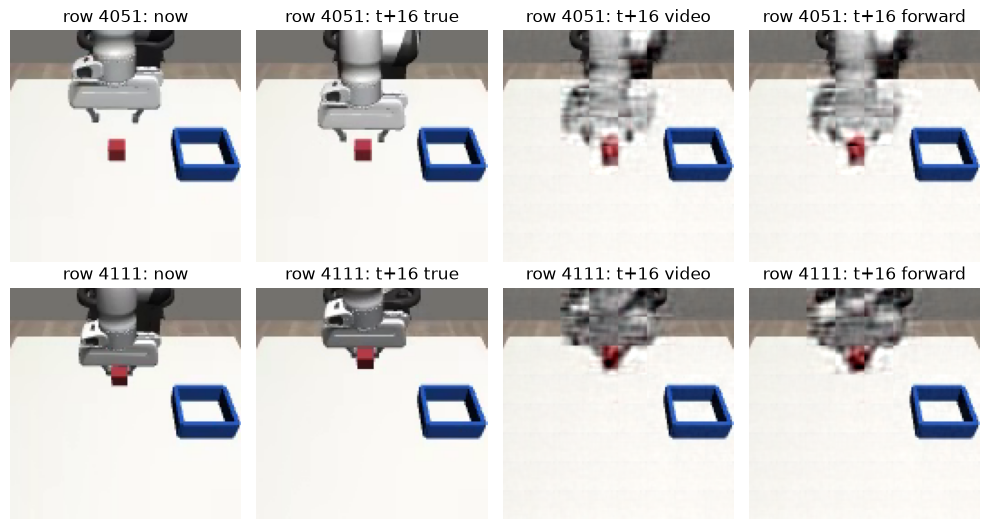

In [62]:
torch.manual_seed(0)
shown = {
    'now': TOP[moments].float() / 255,
    't+16 true': truth(moments),
    't+16 video': sample_frame(uwmxx, moments),
    't+16 forward': sample_frame(uwmxx, moments, True),
}
fig, axs = plt.subplots(2, 4, figsize=(10, 5.4))
for i, (name, ims) in enumerate(shown.items()):
    for m in range(2):
        axs[m, i].imshow(ims[m].permute(1, 2, 0).cpu())
        axs[m, i].set_title(f'row {moments[m].item()}: {name}')
        axs[m, i].axis('off')
plt.tight_layout()
plt.show()

### step 29 — blurry because of the sampler? The video frame at 10, 25 and 50 Euler steps

Same `UWMxx`, same two moments of demo 19; only `steps` in `sample_frame` changes. Sharper with more steps → the blur came from the coarse last jump (τ 0.9 → 1 straight to ĉ); unchanged → it's the frame half's capacity.


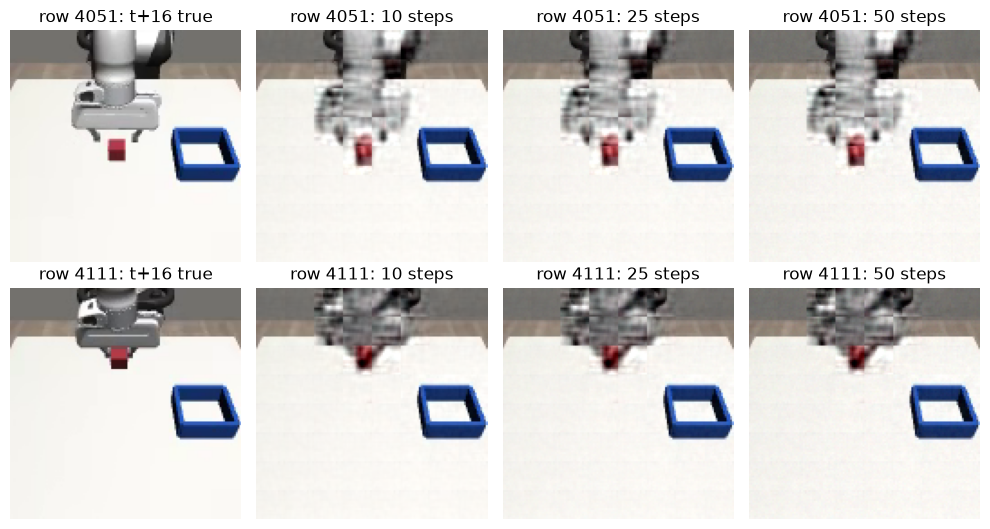

In [63]:
shown = {'t+16 true': truth(moments)}
for steps in (10, 25, 50):
    torch.manual_seed(0)  # same starting noise for every column
    shown[f'{steps} steps'] = sample_frame(uwmxx, moments, steps=steps)
fig, axs = plt.subplots(2, 4, figsize=(10, 5.4))
for i, (name, ims) in enumerate(shown.items()):
    for m in range(2):
        axs[m, i].imshow(ims[m].permute(1, 2, 0).cpu())
        axs[m, i].set_title(f'row {moments[m].item()}: {name}')
        axs[m, i].axis('off')
plt.tight_layout()
plt.show()

### step 30 — the joint job: frame and chunk denoised **together**, as the policy

Step 16's `predict` leaves the frame as noise (τ_v = 0). Here both levels run 0 → 1 in lockstep, so at every step the action tokens read an imagined t+16 frame that is getting clearer: "picture the outcome while deciding". Training drew τ_v and τ_a independently, so equal pairs were seen. Same `UWMxx` weights, same sweep; `UWMxx` with the frame left as noise: 16/20, 16/20.


In [64]:
@torch.no_grad()
def predict_joint(net: UWM, seen: list[np.ndarray], obs, steps: int = 10) -> np.ndarray:
    # step 16's predict, with the frame denoised alongside the chunk
    now = len(seen) - 1
    ims = np.stack([seen[max(0, now + o)] for o in (-12, -8, -4, 0)])  # [4, H, W, 3]
    past_ims = torch.from_numpy(ims).permute(0, 3, 1, 2)[None].to(device).float() / 255
    joints = torch.from_numpy(obs.state)[None].to(device)  # [1, 8]
    x_f = torch.randn(1, 64, 768, device=device)
    x_a = torch.randn(1, 16, 8, device=device)
    for k in range(steps):
        tau = torch.full((1,), k / steps, device=device)  # the same level for both parts
        with torch.autocast('cuda', dtype=torch.bfloat16):
            v_f, v_a = net(past_ims, joints, x_f, x_a, tau, tau)
        x_f = x_f + v_f.float() / steps
        x_a = x_a + v_a.float() / steps
    chunk_np = (x_a * A_STD + A_MEAN)[0].cpu().numpy()  # [16, 8] radians
    chunk_np[:, 7] = np.clip(chunk_np[:, 7], 0.0, 1.0)
    return chunk_np


def rollout_joint(net: UWM, seed: int, n_exec: int) -> tuple[bool, str, int]:
    # step 16's rollout, planning with predict_joint
    obs = env.reset(seed=seed)
    seen = [obs.images['top']]
    plan = []
    for step in range(600):
        if not plan:
            plan = list(predict_joint(net, seen, obs)[:n_exec])
        r = env.step(plan.pop(0))
        obs = r.observation
        seen.append(obs.images['top'])
        if r.terminated or r.truncated:
            break
    return r.success, str(r.failure_mode), step + 1

In [65]:
@cache
def sweep_joint(
    n_exec: int, model: str = 'xx', train_seed: int = 0, train_steps: int = 10000
) -> dict[int, tuple]:
    # sweep_xx, planning with the joint job; model 'uwm' = UWM / train, 'xx' = UWMxx / train_xx
    cls, trainer = {'uwm': (UWM, train), 'xx': (UWMxx, train_xx)}[model]
    net = cls().to(device)
    with contextlib.redirect_stdout(io.StringIO()):
        net.load_state_dict(trainer(seed=train_seed, steps=train_steps))
    net.eval()
    torch.manual_seed(n_exec)  # the sampling noise, fixed per call
    res = {seed: rollout_joint(net, seed, n_exec) for seed in range(1000, 1020)}
    fails = Counter(mode for ok, mode, _ in res.values() if not ok)
    print(
        f'{model:3s} n_exec {n_exec:2d}: {sum(ok for ok, _, _ in res.values()):2d}/20'
        f'   failures {dict(fails)}'
    )
    return res

sweep_joint: cached, 4 call(s) stored


In [66]:
sweeps_joint = {
    (model, n_exec): sweep_joint(n_exec, model) for model in ['uwm', 'xx'] for n_exec in [8, 16]
}
print('frame left as noise: uwm 16, 16;  xx 16, 16;  UVA: 19, 20')

uwm n_exec  8: 18/20   failures {'no_grasp': 2}
uwm n_exec 16: 16/20   failures {'dropped': 2, 'no_grasp': 2}
xx  n_exec  8: 16/20   failures {'no_grasp': 4}
xx  n_exec 16: 16/20   failures {'no_grasp': 4}
frame left as noise: uwm 16, 16;  xx 16, 16;  UVA: 19, 20


### wrap-up — what UWM buys, where it fails (T1, 20 train demos, ONE training seed)

**Buys**
- One network, four jobs, picked by two noise levels: policy (frame left as noise), inverse (t+16 frame given), video, forward.
- `UWMxx` (both heads say the clean answer): **32/40** in the sim, the same as UWM, **and** imagined frames that work (pixel MSE 0.0046 vs copy-the-current-frame 0.017; UWM's were 0.114, still noise).
- The inverse job for free: given the true t+16 frame, first-action error ~10% lower, from the same weights.
- First arm action 0.0052 rad, better than UVA's 0.0062.

**Fails**
- Behind UVA on T1: 32/40 vs 39/40, mostly `no_grasp`.
- Frames are blurry where it matters: the static scene is clean, the arm is a blocky patch mosaic. Pixel MSE rewards the background.
- The actions barely read the frame: denoising frame and chunk together changed nothing (34/40 vs 32/40, 32/40 vs 32/40).
- The form of the frame loss decides whether the policy survives: a velocity head gives noise frames, a clean-patch head with the 1/(1−τ)² loss drops the policy to 9/40, a plain clean MSE keeps it.
- Val error doesn't rank the sim results (gripper error 0.0223 → 32/40, 0.0289 → 9/40, 0.0307 → 22/40). Only rollouts count.
- One training seed per arm, 20 sim seeds each: differences of ±2/40 are noise. Seeds 1 and 2 not run.

**Next** → `uwm2.ipynb`: does action-free video help when labels are scarce (10 labelled demos + 80 video-only vs 10 alone)? Parked: seeds 1, 2; frame-first lag schedule; a conv decoder for sharper frames.